'''
MILESTONE 2

Nama  : Muhammad Rifqi Sahib

Batch : CODA-RMT-021

Program ini dibuat untuk mengerjakan MILESTONE 2

'''

https://datastudio.google.com/reporting/7f18e008-c43c-4fe3-9910-56b8084e7d6e

# **Analisis Data TransJakarta**

### **Latar Belakang**

TransJakarta merupakan salah satu transportasi umum yang dapat digunakan di daerah Jakarta. Tingginya aktivitas perjalanan menyebabkan operator perlu memahami pola penggunaan layanan agar dapat mengoptimalkan pengelolaan koridor, halte, dan waktu operasional. Data transaksi perjalanan dapat memberikan gambaran mengenai bagaimana masyarakat menggunakan layanan TransJakarta, seperti waktu perjalanan, koridor yang digunakan, halte keberangkatan dan tujuan, arah perjalanan, serta karakteristik pengguna. Informasi tersebut dapat dimanfaatkan untuk mengetahui periode dengan aktivitas perjalanan tinggi, koridor yang paling banyak digunakan, serta pola perjalanan pengguna. Oleh karena itu, diperlukan analisis terhadap data transaksi TransJakarta untuk mengidentifikasi pola penggunaan layanan dan mengetahui karakteristik perjalanan pengguna. Hasil analisis tersebut diharapkan dapat memberikan informasi kepada manajemen TransJakarta mengenai kondisi penggunaan TransJakarta sehingga dapat menjadi bahan pertimbangan dalam meningkatkan efektivitas dan kualitas layanan transportasi umum.

### **Tujuan**

Untuk menganalisis pola penggunaan layanan TransJakarta berdasarkan data transaksi perjalanan, dengan fokus pada waktu perjalanan, koridor, halte keberangkatan dan tujuan, serta karakteristik pengguna. Analisis dilakukan untuk mengidentifikasi waktu dengan aktivitas perjalanan tertinggi, koridor dan halte yang memiliki tingkat penggunaan tinggi, serta karakteristik pola perjalanan pengguna TransJakarta.

### **Client**

Manajemen TransJakarta

## **Problem Statement**

Bagaimana pola penggunaan layanan TransJakarta berdasarkan waktu perjalanan, koridor, halte keberangkatan dan tujuan, serta karakteristik perjalanan pengguna, sehingga dapat diketahui periode aktivitas tertinggi, titik layanan yang paling banyak digunakan, dan hubungan antara jumlah halte yang dilewati dengan durasi perjalanan?

## **SMART**

**Specific:**
Menganalisis pola dan karakteristik perjalanan penumpang TransJakarta berdasarkan waktu, koridor, halte asal-tujuan, panjang perjalanan, dan durasi perjalanan.

**Measurable:**
Diukur menggunakan jumlah transaksi, jumlah perjalanan per jam dan koridor, jumlah tap-in/tap-out, jumlah halte yang dilewati, serta durasi perjalanan dalam menit.

**Achievable:**
Analisis menggunakan variabel yang tersedia dalam dataset TransJakarta seperti transID, tapInTime, tapOutTime, corridorName, tapInStopsName, tapOutStopsName, stopStartSeq, dan stopEndSeq.

**Relevant:**
Hasil analisis dapat memberikan gambaran mengenai pola penggunaan layanan dan konsentrasi perjalanan penumpang TransJakarta.

**Time-bound:**
Analisis dilakukan berdasarkan data perjalanan TransJakarta pada April 2023.

## **5W + 1H**

1. Bagaimana pola perjalanan penumpang TransJakarta selama April 2023?

2. Pada jam berapa jumlah perjalanan TransJakarta mencapai tingkat tertinggi?

3. Koridor mana yang memiliki jumlah perjalanan tertinggi?

4. Halte mana yang paling banyak digunakan sebagai titik keberangkatan dan tujuan?

5. Bagaimana karakteristik dan distribusi durasi perjalanan penumpang TransJakarta?

6. Apakah jumlah halte yang dilewati memiliki hubungan yang signifikan dengan durasi perjalanan penumpang TransJakarta?

### **Import Libraries**

melakukan import library yang digunakan berupa pandas, numpy, matplotlib, dan scipy untuk membantu proses pengolahan data, visualisasi, dan uji statistik.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

### **Data Loading**

meload dataset transaksi TransJakarta yang akan digunakan dalam analisis kemudian menampilkan 10 data teratas untuk melihat struktur awal data.

In [2]:
df = pd.read_csv("/content/dfTransjakarta180kRows.csv")
df.head(10)

,transID,payCardID,payCardBank,payCardName,payCardSex,payCardBirthDate,corridorID,corridorName,direction,tapInStops,...,tapInStopsLon,stopStartSeq,tapInTime,tapOutStops,tapOutStopsName,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount
0,VRPJ892P3M98RA,3561407960318444,dki,"Dr. Janet Nashiruddin, M.Ak",M,2010,4,Pulo Gadung 2 - Tosari,1.0,P00167,...,106.89165,12.0,2023-04-03 06:53:02,P00127,Layur,-6.193539,106.89909,13.0,2023-04-03 07:13:28,3500.0
1,ZWCH834I6M26HS,347728053419394,emoney,Balamantri Rahayu,M,2002,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,...,106.86298,27.0,2023-04-03 05:59:19,B00865P,Jln. Ar Ridho,-6.308148,106.86935,30.0,2023-04-03 06:57:06,0.0
2,YRLD835V6L82GO,377105453850671,emoney,Dian Mustofa,F,1993,B13,Bekasi Barat - Blok M,1.0,B02192P,...,106.99215,6.0,2023-04-03 05:13:24,B00108P,Bandar Djakarta Bekasi,-6.227085,106.99683,9.0,2023-04-03 06:01:23,20000.0
3,ZZBX143N6N83HQ,4486493302356581,dki,"Cut Janet Suryatmi, M.Ak",M,1980,8K,Batusari - Grogol,1.0,B03637P,...,106.78213,16.0,2023-04-03 05:20:24,NaN,Yayasan Alkahfi Jakbar,-6.198896,106.76889,26.0,2023-04-03 06:01:25,3500.0
4,EWEG491A2W45DR,30139379978125,bni,"dr. Mulyanto Pudjiastuti, M.Ak",F,1997,NaN,NaN,0.0,NaN,...,106.83514,2.0,2023-04-03 06:00:54,B02755P,Perpustakaan Nasional,-6.180673,106.82643,5.0,2023-04-03 06:47:32,3500.0
5,KTGG277R2I90ZB,30394281967910,bni,"Dasa Prakasa, S.I.Kom",F,1993,JAK.117,Tanjung Priok - Tanah Merdeka,1.0,B04272P,...,106.89638,17.0,2023-04-03 05:06:00,B04818P,Simpang Gotong Royong 2,-6.125482,106.89331,21.0,2023-04-03 05:41:04,0.0
6,VSJU956Z4T24LI,4974829151599657,dki,Elvina Hasanah,M,1966,9F,Rusun Tambora - Pluit,0.0,P00090,...,106.79352,5.0,2023-04-03 06:21:07,P00170,Penjaringan,-6.126306,106.79203,7.0,2023-04-03 06:52:58,0.0
7,HBMD368H3K77KW,3532177104809428,dki,"Perkasa Prakasa, M.Pd",F,2011,JAK.31,Blok M - Andara,0.0,B00042P,...,106.80369,55.0,2023-04-03 06:34:03,B01147P,Jln. H. Terin Pangkalan Jati,-6.327961,106.80054,56.0,2023-04-03 07:32:53,0.0
8,SQHG432Q6Z10BR,3537522260639116,dki,Ayu Wahyudin,F,2009,JAK.37,Cililitan - Condet via Kayu Manis,1.0,B05218P,...,106.85862,10.0,2023-04-03 05:48:17,B00405P,Gg. Ani Raya Condet,-6.266674,106.86054,37.0,2023-04-03 06:13:38,0.0
9,EHWL093H6L20UL,4677151756111287186,brizzi,"H. Xanana Santoso, S.Farm",M,2010,JAK.15,Bulak Turi - Tanjung Priok,0.0,B01327P,...,106.89550,46.0,2023-04-03 05:09:13,B05728P,Term. Tj. Priok 1,-6.109800,106.88118,52.0,2023-04-03 06:07:24,0.0


memeriksa informasi dataset untuk melihat jumlah data, nama kolom, tipe data, dan informasi awal mengenai struktur dataset.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13306 entries, 0 to 13305
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   transID           13306 non-null  object 
 1   payCardID         13306 non-null  int64  
 2   payCardBank       13306 non-null  object 
 3   payCardName       13306 non-null  object 
 4   payCardSex        13306 non-null  object 
 5   payCardBirthDate  13306 non-null  int64  
 6   corridorID        12829 non-null  object 
 7   corridorName      12386 non-null  object 
 8   direction         13306 non-null  float64
 9   tapInStops        12821 non-null  object 
 10  tapInStopsName    13306 non-null  object 
 11  tapInStopsLat     13305 non-null  float64
 12  tapInStopsLon     13305 non-null  float64
 13  stopStartSeq      13305 non-null  float64
 14  tapInTime         13305 non-null  object 
 15  tapOutStops       12473 non-null  object 
 16  tapOutStopsName   12852 non-null  object

memeriksa jumlah missing values pada setiap kolom untuk mengetahui apakah terdapat data yang kosong sebelum dilakukan proses pembersihan.

In [4]:
df.isnull().sum()

,0
transID,0
payCardID,0
payCardBank,0
payCardName,0
payCardSex,0
payCardBirthDate,0
corridorID,477
corridorName,920
direction,0
tapInStops,485


### **Data Cleaning**

menghapus kolom yang berkaitan dengan identitas pribadi pengguna karena tidak digunakan dalam analisis pola perjalanan dan dapat mengurangi informasi yang bersifat sensitif.

In [5]:
drop_columns = [
    "payCardID",
    "payCardName",
    "payCardBirthDate"
]

df_clean = df.drop(columns=drop_columns)

print("Ukuran dataset setelah drop kolom:", df_clean.shape)
display(df_clean.head())

Ukuran dataset setelah drop kolom: (13306, 19)


,transID,payCardBank,payCardSex,corridorID,corridorName,direction,tapInStops,tapInStopsName,tapInStopsLat,tapInStopsLon,stopStartSeq,tapInTime,tapOutStops,tapOutStopsName,tapOutStopsLat,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount
0,VRPJ892P3M98RA,dki,M,4,Pulo Gadung 2 - Tosari,1.0,P00167,Pemuda Rawamangun,-6.193488,106.89165,12.0,2023-04-03 06:53:02,P00127,Layur,-6.193539,106.89909,13.0,2023-04-03 07:13:28,3500.0
1,ZWCH834I6M26HS,emoney,M,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,Sekolah Islam PB Soedirman,-6.314293,106.86298,27.0,2023-04-03 05:59:19,B00865P,Jln. Ar Ridho,-6.308148,106.86935,30.0,2023-04-03 06:57:06,0.0
2,YRLD835V6L82GO,emoney,F,B13,Bekasi Barat - Blok M,1.0,B02192P,Mall Metropolitan,-6.247861,106.99215,6.0,2023-04-03 05:13:24,B00108P,Bandar Djakarta Bekasi,-6.227085,106.99683,9.0,2023-04-03 06:01:23,20000.0
3,ZZBX143N6N83HQ,dki,M,8K,Batusari - Grogol,1.0,B03637P,Sbr. Jln. Angsana Kemanggisan,-6.194813,106.78213,16.0,2023-04-03 05:20:24,NaN,Yayasan Alkahfi Jakbar,-6.198896,106.76889,26.0,2023-04-03 06:01:25,3500.0
4,EWEG491A2W45DR,bni,F,NaN,NaN,0.0,NaN,BRI Menteng,-6.186792,106.83514,2.0,2023-04-03 06:00:54,B02755P,Perpustakaan Nasional,-6.180673,106.82643,5.0,2023-04-03 06:47:32,3500.0


mengubah kolom tapInTime dan tapOutTime menjadi tipe datetime agar dapat digunakan untuk menghitung waktu dan durasi perjalanan.

In [6]:
df_clean["tapInTime"] = pd.to_datetime(
    df_clean["tapInTime"],
    errors="coerce"
)

df_clean["tapOutTime"] = pd.to_datetime(
    df_clean["tapOutTime"],
    errors="coerce"
)

print(df_clean[["tapInTime", "tapOutTime"]].dtypes)

tapInTime     datetime64[ns]
tapOutTime    datetime64[ns]
dtype: object


membersihkan kolom bertipe teks dengan menghapus spasi yang tidak diperlukan agar nilai kategori seperti nama koridor dan nama halte menjadi lebih konsisten.

In [7]:
text_columns = [
    "payCardBank",
    "payCardSex",
    "corridorName",
    "tapInStopsName",
    "tapOutStopsName"
]

for col in text_columns:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

memeriksa data duplikat kemudian menghapus data yang sama agar tidak terjadi perhitungan transaksi ganda dalam analisis.

In [8]:
print("Jumlah duplikat:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Jumlah data setelah menghapus duplikat:", len(df_clean))

Jumlah duplikat: 0
Jumlah data setelah menghapus duplikat: 13306


menghitung durasi perjalanan penumpang dalam satuan menit berdasarkan selisih antara waktu tap out dan waktu tap in.

In [9]:
df_clean["travel_duration_min"] = (
    df_clean["tapOutTime"] - df_clean["tapInTime"]
).dt.total_seconds() / 60

memeriksa durasi perjalanan yang tidak valid, yaitu durasi yang bernilai nol atau negatif, karena data tersebut tidak dapat digunakan untuk analisis durasi.

In [10]:
invalid_duration = (
    df_clean["travel_duration_min"].notna() &
    (df_clean["travel_duration_min"] <= 0)
)

print("Durasi tidak valid:", invalid_duration.sum())

Durasi tidak valid: 0


memilih data yang memiliki durasi perjalanan valid, yaitu data dengan durasi lebih dari nol, untuk digunakan pada analisis selanjutnya.

In [11]:
df_duration = df_clean[
    df_clean["travel_duration_min"].notna() &
    (df_clean["travel_duration_min"] > 0)
].copy()

print("Data untuk analisis durasi:", df_duration.shape)

Data untuk analisis durasi: (12852, 20)


menghitung jumlah halte yang dilewati berdasarkan selisih urutan halte akhir dan urutan halte awal.

In [12]:
df_clean["jumlah_halte"] = (
    df_clean["stopEndSeq"] - df_clean["stopStartSeq"]
)

memeriksa jumlah perjalanan dengan jumlah halte kurang dari atau sama dengan nol untuk memastikan nilai jumlah halte yang digunakan dalam analisis valid.

In [13]:
print(
    "Jumlah perjalanan dengan jumlah halte <= 0:",
    (df_clean["jumlah_halte"] <= 0).sum()
)

Jumlah perjalanan dengan jumlah halte <= 0: 0


### **Feature Engineering**

membuat beberapa variabel baru dari data waktu, yaitu tanggal perjalanan, jam perjalanan, dan nama hari untuk membantu analisis pola perjalanan.

In [14]:
df_clean["travel_date"] = df_clean["tapInTime"].dt.date

df_clean["hour"] = df_clean["tapInTime"].dt.hour

df_clean["day_name"] = df_clean["tapInTime"].dt.day_name()

memeriksa jumlah data dan distribusi transaksi berdasarkan jam untuk melihat rentang waktu perjalanan yang terdapat pada dataset.

In [15]:
print("Jumlah data:", len(df_clean))

print("\nNilai Hour:")
print(sorted(df_clean["hour"].dropna().unique()))

print("\nJumlah transaksi berdasarkan Hour:")
print(df_clean["hour"].value_counts().sort_index())

Jumlah data: 13306

Nilai Hour:
[np.float64(5.0), np.float64(6.0), np.float64(16.0), np.float64(17.0)]

Jumlah transaksi berdasarkan Hour:
hour
5.0     3650
6.0     3655
16.0    3007
17.0    2993
Name: count, dtype: int64


mengelompokkan jam perjalanan ke dalam kategori waktu Morning, Noon, Afternoon, dan Evening agar pola perjalanan dapat dilihat berdasarkan periode waktu.

In [16]:
def categorize_time(hour):
    if pd.isna(hour):
        return np.nan
    elif 5 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 15:
        return "Noon"
    elif 15 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

df_clean["time_category"] = df_clean["hour"].apply(categorize_time)

melakukan pengecekan akhir terhadap ukuran dataset, beberapa data teratas, serta tipe data setelah proses cleaning dan feature engineering.

In [17]:
print("Jumlah baris:", df_clean.shape[0])
print("Jumlah kolom:", df_clean.shape[1])

display(df_clean.head())

df_clean.info()

Jumlah baris: 13306
Jumlah kolom: 25


,transID,payCardBank,payCardSex,corridorID,corridorName,direction,tapInStops,tapInStopsName,tapInStopsLat,tapInStopsLon,...,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,travel_duration_min,jumlah_halte,travel_date,hour,day_name,time_category
0,VRPJ892P3M98RA,dki,M,4,Pulo Gadung 2 - Tosari,1.0,P00167,Pemuda Rawamangun,-6.193488,106.89165,...,106.89909,13.0,2023-04-03 07:13:28,3500.0,20.433333,1.0,2023-04-03,6.0,Monday,Morning
1,ZWCH834I6M26HS,emoney,M,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,Sekolah Islam PB Soedirman,-6.314293,106.86298,...,106.86935,30.0,2023-04-03 06:57:06,0.0,57.783333,3.0,2023-04-03,5.0,Monday,Morning
2,YRLD835V6L82GO,emoney,F,B13,Bekasi Barat - Blok M,1.0,B02192P,Mall Metropolitan,-6.247861,106.99215,...,106.99683,9.0,2023-04-03 06:01:23,20000.0,47.983333,3.0,2023-04-03,5.0,Monday,Morning
3,ZZBX143N6N83HQ,dki,M,8K,Batusari - Grogol,1.0,B03637P,Sbr. Jln. Angsana Kemanggisan,-6.194813,106.78213,...,106.76889,26.0,2023-04-03 06:01:25,3500.0,41.016667,10.0,2023-04-03,5.0,Monday,Morning
4,EWEG491A2W45DR,bni,F,NaN,NaN,0.0,NaN,BRI Menteng,-6.186792,106.83514,...,106.82643,5.0,2023-04-03 06:47:32,3500.0,46.633333,3.0,2023-04-03,6.0,Monday,Morning


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13306 entries, 0 to 13305
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   transID              13306 non-null  object        
 1   payCardBank          13306 non-null  object        
 2   payCardSex           13306 non-null  object        
 3   corridorID           12829 non-null  object        
 4   corridorName         12386 non-null  object        
 5   direction            13306 non-null  float64       
 6   tapInStops           12821 non-null  object        
 7   tapInStopsName       13306 non-null  object        
 8   tapInStopsLat        13305 non-null  float64       
 9   tapInStopsLon        13305 non-null  float64       
 10  stopStartSeq         13305 non-null  float64       
 11  tapInTime            13305 non-null  datetime64[ns]
 12  tapOutStops          12473 non-null  object        
 13  tapOutStopsName      12852 non-

memeriksa kembali missing values setelah proses cleaning untuk mengetahui kolom yang masih memiliki data kosong dan persentasenya.

In [18]:
missing_after = pd.DataFrame({
    "Jumlah Missing": df_clean.isnull().sum(),
    "Persentase (%)": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_after = missing_after[
    missing_after["Jumlah Missing"] > 0
].sort_values(
    "Jumlah Missing",
    ascending=False
)

display(missing_after)

,Jumlah Missing,Persentase (%)
corridorName,920,6.91
tapOutStops,833,6.26
tapInStops,485,3.64
corridorID,477,3.58
stopEndSeq,454,3.41
tapOutStopsLon,454,3.41
tapOutStopsLat,454,3.41
tapOutStopsName,454,3.41
travel_duration_min,454,3.41
jumlah_halte,454,3.41


menyiapkan data yang memiliki waktu tap in untuk digunakan pada analisis pola perjalanan berdasarkan waktu.

In [19]:
df_time = df_clean[
    df_clean["tapInTime"].notna()
].copy()

menyiapkan data yang memiliki nama koridor untuk digunakan pada analisis jumlah perjalanan berdasarkan koridor.

In [20]:
df_corridor = df_clean[
    df_clean["corridorName"].notna()
].copy()

menyiapkan data yang memiliki halte keberangkatan dan halte tujuan untuk digunakan pada analisis penggunaan halte.

In [21]:
df_stop = df_clean[
    df_clean["tapInStopsName"].notna() &
    df_clean["tapOutStopsName"].notna()
].copy()

menyiapkan data yang memiliki informasi jenis kelamin untuk digunakan apabila diperlukan dalam melihat karakteristik pengguna.

In [22]:
df_gender = df_clean[
    df_clean["payCardSex"].notna()
].copy()

menyiapkan data dengan waktu tap in dan tap out yang valid serta durasi perjalanan lebih dari nol untuk analisis durasi.

In [23]:
df_duration = df_clean[
    df_clean["tapInTime"].notna() &
    df_clean["tapOutTime"].notna() &
    (df_clean["travel_duration_min"] > 0)
].copy()

menampilkan kembali beberapa data teratas sebagai pengecekan sebelum dataset digunakan pada tahap analisis.

In [24]:
df_clean.head(10)

,transID,payCardBank,payCardSex,corridorID,corridorName,direction,tapInStops,tapInStopsName,tapInStopsLat,tapInStopsLon,...,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,travel_duration_min,jumlah_halte,travel_date,hour,day_name,time_category
0,VRPJ892P3M98RA,dki,M,4,Pulo Gadung 2 - Tosari,1.0,P00167,Pemuda Rawamangun,-6.193488,106.89165,...,106.89909,13.0,2023-04-03 07:13:28,3500.0,20.433333,1.0,2023-04-03,6.0,Monday,Morning
1,ZWCH834I6M26HS,emoney,M,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,Sekolah Islam PB Soedirman,-6.314293,106.86298,...,106.86935,30.0,2023-04-03 06:57:06,0.0,57.783333,3.0,2023-04-03,5.0,Monday,Morning
2,YRLD835V6L82GO,emoney,F,B13,Bekasi Barat - Blok M,1.0,B02192P,Mall Metropolitan,-6.247861,106.99215,...,106.99683,9.0,2023-04-03 06:01:23,20000.0,47.983333,3.0,2023-04-03,5.0,Monday,Morning
3,ZZBX143N6N83HQ,dki,M,8K,Batusari - Grogol,1.0,B03637P,Sbr. Jln. Angsana Kemanggisan,-6.194813,106.78213,...,106.76889,26.0,2023-04-03 06:01:25,3500.0,41.016667,10.0,2023-04-03,5.0,Monday,Morning
4,EWEG491A2W45DR,bni,F,NaN,NaN,0.0,NaN,BRI Menteng,-6.186792,106.83514,...,106.82643,5.0,2023-04-03 06:47:32,3500.0,46.633333,3.0,2023-04-03,6.0,Monday,Morning
5,KTGG277R2I90ZB,bni,F,JAK.117,Tanjung Priok - Tanah Merdeka,1.0,B04272P,Sbr. RPTRA Radar Pembangunan,-6.120126,106.89638,...,106.89331,21.0,2023-04-03 05:41:04,0.0,35.066667,4.0,2023-04-03,5.0,Monday,Morning
6,VSJU956Z4T24LI,dki,M,9F,Rusun Tambora - Pluit,0.0,P00090,Jembatan Dua,-6.143279,106.79352,...,106.79203,7.0,2023-04-03 06:52:58,0.0,31.850000,2.0,2023-04-03,6.0,Monday,Morning
7,HBMD368H3K77KW,dki,F,JAK.31,Blok M - Andara,0.0,B00042P,Andara Margasatwa 1,-6.313471,106.80369,...,106.80054,56.0,2023-04-03 07:32:53,0.0,58.833333,1.0,2023-04-03,6.0,Monday,Morning
8,SQHG432Q6Z10BR,dki,F,JAK.37,Cililitan - Condet via Kayu Manis,1.0,B05218P,Simpang Waru Tengah,-6.293301,106.85862,...,106.86054,37.0,2023-04-03 06:13:38,0.0,25.350000,27.0,2023-04-03,5.0,Monday,Morning
9,EHWL093H6L20UL,brizzi,M,JAK.15,Bulak Turi - Tanjung Priok,0.0,B01327P,Jln. Lorong 5,-6.107716,106.89550,...,106.88118,52.0,2023-04-03 06:07:24,0.0,58.183333,6.0,2023-04-03,5.0,Monday,Morning


menyimpan dataset yang sudah dibersihkan ke dalam file csv agar hasil preprocessing dapat digunakan kembali pada tahap berikutnya.

In [25]:
df_clean.to_csv(
    "dfTransjakarta_clean.csv",
    index=False
)

print("Dataset clean berhasil disimpan!")

Dataset clean berhasil disimpan!


### **Feature Engineering**

membentuk kembali variabel yang diperlukan untuk analisis, seperti tanggal, jam, hari, durasi perjalanan, dan jumlah halte yang dilewati.

In [26]:
df_clean["tapInTime"] = pd.to_datetime(
    df_clean["tapInTime"],
    errors="coerce"
)

df_clean["tapOutTime"] = pd.to_datetime(
    df_clean["tapOutTime"],
    errors="coerce"
)

df_clean["travel_date"] = df_clean["tapInTime"].dt.date

df_clean["hour"] = df_clean["tapInTime"].dt.hour

df_clean["day_name"] = df_clean["tapInTime"].dt.day_name()

df_clean["travel_duration_min"] = (
    df_clean["tapOutTime"] - df_clean["tapInTime"]
).dt.total_seconds() / 60

df_clean["jumlah_halte"] = (
    pd.to_numeric(df_clean["stopEndSeq"], errors="coerce")
    - pd.to_numeric(df_clean["stopStartSeq"], errors="coerce")
)

display(df_clean.head())

,transID,payCardBank,payCardSex,corridorID,corridorName,direction,tapInStops,tapInStopsName,tapInStopsLat,tapInStopsLon,...,tapOutStopsLon,stopEndSeq,tapOutTime,payAmount,travel_duration_min,jumlah_halte,travel_date,hour,day_name,time_category
0,VRPJ892P3M98RA,dki,M,4,Pulo Gadung 2 - Tosari,1.0,P00167,Pemuda Rawamangun,-6.193488,106.89165,...,106.89909,13.0,2023-04-03 07:13:28,3500.0,20.433333,1.0,2023-04-03,6.0,Monday,Morning
1,ZWCH834I6M26HS,emoney,M,JAK.28,Kp. Rambutan - Taman Wiladatika,1.0,B04633P,Sekolah Islam PB Soedirman,-6.314293,106.86298,...,106.86935,30.0,2023-04-03 06:57:06,0.0,57.783333,3.0,2023-04-03,5.0,Monday,Morning
2,YRLD835V6L82GO,emoney,F,B13,Bekasi Barat - Blok M,1.0,B02192P,Mall Metropolitan,-6.247861,106.99215,...,106.99683,9.0,2023-04-03 06:01:23,20000.0,47.983333,3.0,2023-04-03,5.0,Monday,Morning
3,ZZBX143N6N83HQ,dki,M,8K,Batusari - Grogol,1.0,B03637P,Sbr. Jln. Angsana Kemanggisan,-6.194813,106.78213,...,106.76889,26.0,2023-04-03 06:01:25,3500.0,41.016667,10.0,2023-04-03,5.0,Monday,Morning
4,EWEG491A2W45DR,bni,F,NaN,NaN,0.0,NaN,BRI Menteng,-6.186792,106.83514,...,106.82643,5.0,2023-04-03 06:47:32,3500.0,46.633333,3.0,2023-04-03,6.0,Monday,Morning


### **Q1 - Pola Perjalanan per Tanggal**

mengelompokkan transaksi berdasarkan tanggal untuk melihat perubahan jumlah perjalanan penumpang selama April 2023 dan menampilkannya dalam bentuk grafik.

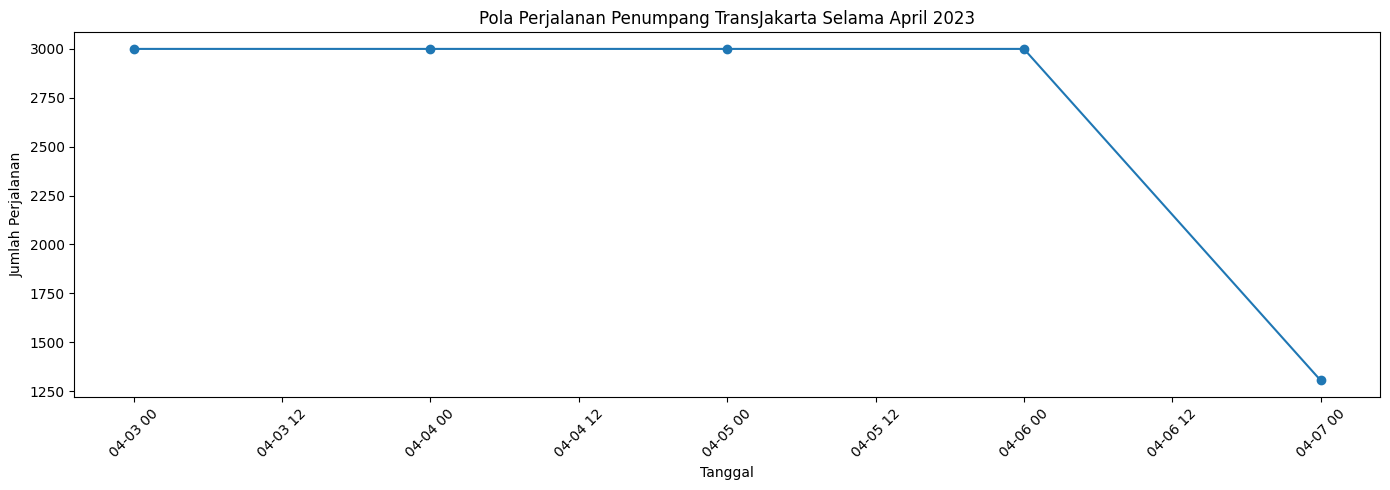

In [27]:
# ==============================
# Q1 - POLA PERJALANAN PER TANGGAL
# ==============================

daily_trips = (
    df_clean
    .dropna(subset=["travel_date"])
    .groupby("travel_date")["transID"]
    .count()
    .reset_index(name="jumlah_perjalanan")
)

daily_trips["travel_date"] = pd.to_datetime(
    daily_trips["travel_date"]
)

plt.figure(figsize=(14, 5))

plt.plot(
    daily_trips["travel_date"],
    daily_trips["jumlah_perjalanan"],
    marker="o"
)

plt.title(
    "Pola Perjalanan Penumpang TransJakarta Selama April 2023"
)

plt.xlabel("Tanggal")
plt.ylabel("Jumlah Perjalanan")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

menentukan tanggal dengan jumlah perjalanan tertinggi dan terendah berdasarkan hasil pengelompokan transaksi per tanggal.

In [28]:
tanggal_tertinggi = daily_trips.loc[
    daily_trips["jumlah_perjalanan"].idxmax()
]

tanggal_terendah = daily_trips.loc[
    daily_trips["jumlah_perjalanan"].idxmin()
]

print(
    "Tanggal dengan perjalanan tertinggi:",
    tanggal_tertinggi["travel_date"].date(),
    "->",
    int(tanggal_tertinggi["jumlah_perjalanan"]),
    "perjalanan"
)

print(
    "Tanggal dengan perjalanan terendah:",
    tanggal_terendah["travel_date"].date(),
    "->",
    int(tanggal_terendah["jumlah_perjalanan"]),
    "perjalanan"
)

Tanggal dengan perjalanan tertinggi: 2023-04-03 -> 3000 perjalanan
Tanggal dengan perjalanan terendah: 2023-04-07 -> 1305 perjalanan


### **Q2 - Pola Perjalanan Berdasarkan Jam**

mengelompokkan transaksi berdasarkan jam tap in untuk mengetahui pola aktivitas perjalanan penumpang sepanjang hari dan menampilkannya dalam bentuk grafik.

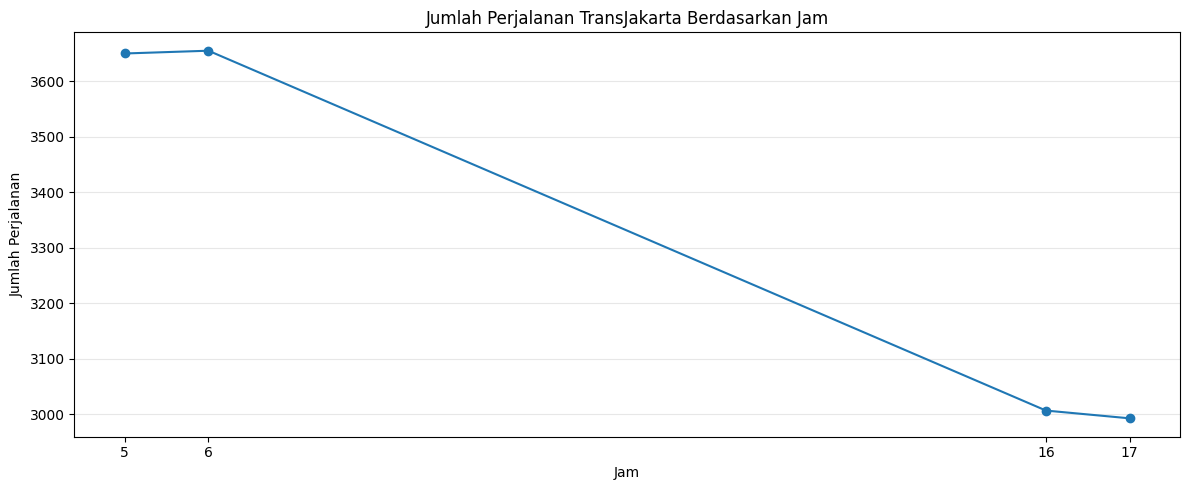

In [29]:
# ==============================
# Q2 - POLA PERJALANAN BERDASARKAN JAM
# ==============================

hourly_trips = (
    df_clean
    .dropna(subset=["hour"])
    .groupby("hour")["transID"]
    .count()
    .reset_index(name="jumlah_perjalanan")
)

hourly_trips["hour"] = hourly_trips["hour"].astype(int)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_trips["hour"],
    hourly_trips["jumlah_perjalanan"],
    marker="o"
)

plt.title(
    "Jumlah Perjalanan TransJakarta Berdasarkan Jam"
)

plt.xlabel("Jam")
plt.ylabel("Jumlah Perjalanan")

plt.xticks(hourly_trips["hour"])

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

menentukan jam dengan jumlah perjalanan tertinggi berdasarkan hasil pengelompokan transaksi per jam.

In [30]:
peak_hour = hourly_trips.loc[
    hourly_trips["jumlah_perjalanan"].idxmax()
]

print(
    f"Jam dengan jumlah perjalanan tertinggi: "
    f"{int(peak_hour['hour']):02d}.00"
)

print(
    f"Jumlah perjalanan: "
    f"{int(peak_hour['jumlah_perjalanan']):,}"
)

Jam dengan jumlah perjalanan tertinggi: 06.00
Jumlah perjalanan: 3,655


### **Q3 - Top 10 Koridor**

menghitung jumlah perjalanan pada setiap koridor kemudian mengambil 10 koridor dengan jumlah perjalanan tertinggi dan menampilkannya dalam bentuk grafik.

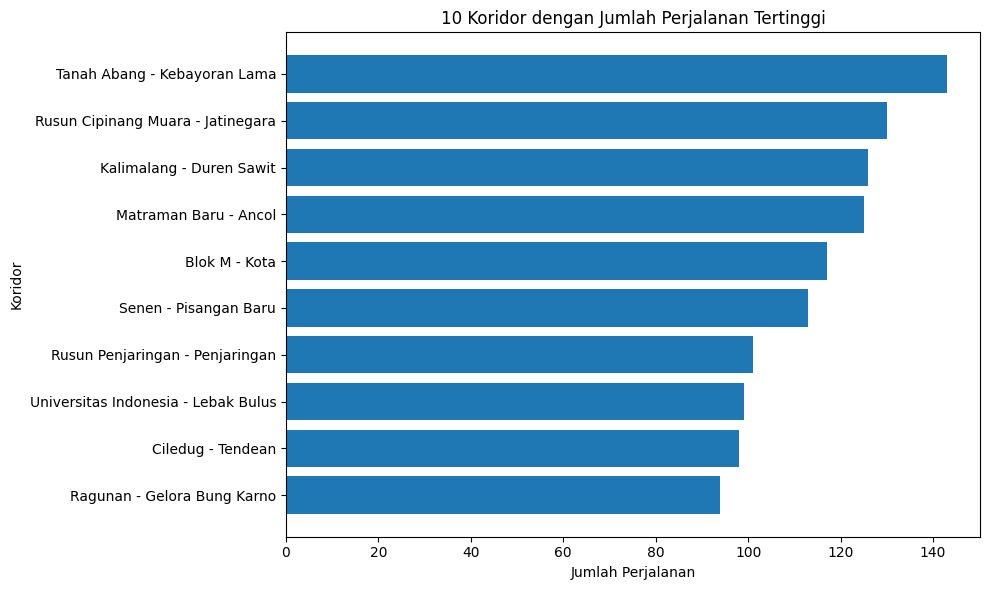

,corridorName,jumlah_perjalanan
191,Tanah Abang - Kebayoran Lama,143
145,Rusun Cipinang Muara - Jatinegara,130
58,Kalimalang - Duren Sawit,126
88,Matraman Baru - Ancol,125
12,Blok M - Kota,117
169,Senen - Pisangan Baru,113
154,Rusun Penjaringan - Penjaringan,101
215,Universitas Indonesia - Lebak Bulus,99
25,Ciledug - Tendean,98
133,Ragunan - Gelora Bung Karno,94


In [31]:
# ==============================
# Q3 - TOP 10 KORIDOR
# ==============================

corridor_trips = (
    df_clean
    .dropna(subset=["corridorName"])
    .groupby("corridorName")["transID"]
    .count()
    .reset_index(name="jumlah_perjalanan")
    .sort_values(
        "jumlah_perjalanan",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    corridor_trips["corridorName"][::-1],
    corridor_trips["jumlah_perjalanan"][::-1]
)

plt.title(
    "10 Koridor dengan Jumlah Perjalanan Tertinggi"
)

plt.xlabel("Jumlah Perjalanan")
plt.ylabel("Koridor")

plt.tight_layout()
plt.show()

display(corridor_trips)

menentukan koridor dengan jumlah perjalanan paling tinggi berdasarkan hasil analisis top 10 koridor.

In [32]:
top_corridor = corridor_trips.iloc[0]

print(
    "Koridor dengan jumlah perjalanan tertinggi:",
    top_corridor["corridorName"]
)

print(
    "Jumlah perjalanan:",
    f"{int(top_corridor['jumlah_perjalanan']):,}"
)

Koridor dengan jumlah perjalanan tertinggi: Tanah Abang - Kebayoran Lama
Jumlah perjalanan: 143


### **Q4A - Top 10 Halte Keberangkatan**

menghitung jumlah transaksi pada setiap halte tap in untuk mengetahui halte yang paling banyak digunakan sebagai titik keberangkatan.

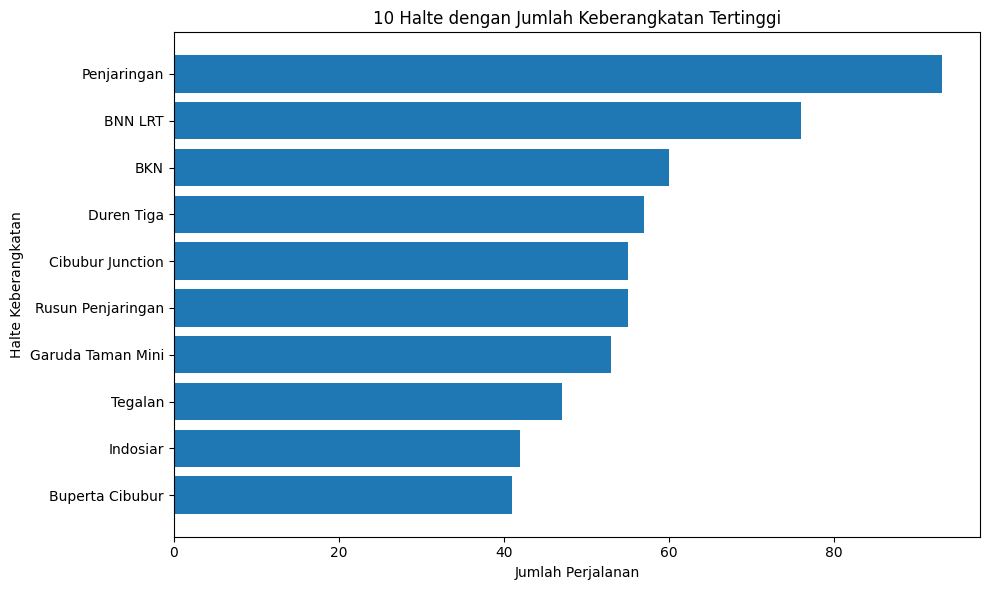

,tapInStopsName,jumlah_perjalanan
936,Penjaringan,93
33,BNN LRT,76
28,BKN,60
154,Duren Tiga,57
114,Cibubur Junction,55
1169,Rusun Penjaringan,55
194,Garuda Taman Mini,53
1734,Tegalan,47
317,Indosiar,42
93,Buperta Cibubur,41


In [33]:
# ==============================
# Q4A - TOP 10 HALTE KEBERANGKATAN
# ==============================

tapin_trips = (
    df_clean
    .dropna(subset=["tapInStopsName"])
    .groupby("tapInStopsName")["transID"]
    .count()
    .reset_index(name="jumlah_perjalanan")
    .sort_values(
        "jumlah_perjalanan",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    tapin_trips["tapInStopsName"][::-1],
    tapin_trips["jumlah_perjalanan"][::-1]
)

plt.title(
    "10 Halte dengan Jumlah Keberangkatan Tertinggi"
)

plt.xlabel("Jumlah Perjalanan")
plt.ylabel("Halte Keberangkatan")

plt.tight_layout()
plt.show()

display(tapin_trips)

### **Q4B - Top 10 Halte Tujuan**

menghitung jumlah transaksi pada setiap halte tap out untuk mengetahui halte yang paling banyak digunakan sebagai titik tujuan perjalanan.

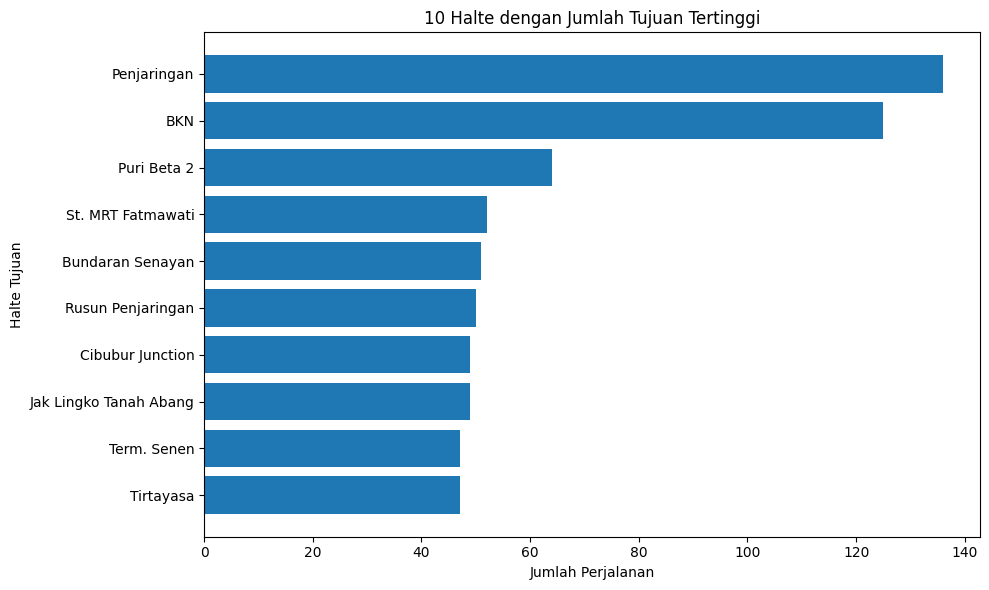

,tapOutStopsName,jumlah_perjalanan
843,Penjaringan,136
30,BKN,125
959,Puri Beta 2,64
1509,St. MRT Fatmawati,52
91,Bundaran Senayan,51
1056,Rusun Penjaringan,50
114,Cibubur Junction,49
311,Jak Lingko Tanah Abang,49
1605,Term. Senen,47
1610,Tirtayasa,47


In [34]:
# ==============================
# Q4B - TOP 10 HALTE TUJUAN
# ==============================

tapout_trips = (
    df_clean
    .dropna(subset=["tapOutStopsName"])
    .groupby("tapOutStopsName")["transID"]
    .count()
    .reset_index(name="jumlah_perjalanan")
    .sort_values(
        "jumlah_perjalanan",
        ascending=False
    )
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    tapout_trips["tapOutStopsName"][::-1],
    tapout_trips["jumlah_perjalanan"][::-1]
)

plt.title(
    "10 Halte dengan Jumlah Tujuan Tertinggi"
)

plt.xlabel("Jumlah Perjalanan")
plt.ylabel("Halte Tujuan")

plt.tight_layout()
plt.show()

display(tapout_trips)

### **Q5 - Data Durasi Valid**

memilih data perjalanan dengan durasi yang valid dan menampilkan jumlah data yang dapat digunakan untuk analisis durasi perjalanan.

In [35]:
# ==============================
# Q5 - DATA DURASI VALID
# ==============================

df_duration = df_clean[
    df_clean["travel_duration_min"].notna() &
    (df_clean["travel_duration_min"] > 0)
].copy()

duration = df_duration["travel_duration_min"]

print(
    "Jumlah data durasi valid:",
    len(duration)
)

Jumlah data durasi valid: 12852


### **Statistik Deskriptif**

menghitung mean, median, standard deviation, minimum, kuartil pertama, kuartil ketiga, maximum, dan IQR untuk mengetahui karakteristik distribusi durasi perjalanan.

In [36]:
# ==============================
# STATISTIK DESKRIPTIF
# ==============================

mean_duration = duration.mean()
median_duration = duration.median()
std_duration = duration.std()

minimum_duration = duration.min()
maximum_duration = duration.max()

Q1 = duration.quantile(0.25)
Q3 = duration.quantile(0.75)

IQR = Q3 - Q1

descriptive_stats = pd.DataFrame({
    "Statistik": [
        "Mean",
        "Median",
        "Standard Deviation",
        "Minimum",
        "Q1",
        "Q3",
        "Maximum",
        "IQR"
    ],
    "Nilai (menit)": [
        mean_duration,
        median_duration,
        std_duration,
        minimum_duration,
        Q1,
        Q3,
        maximum_duration,
        IQR
    ]
})

display(descriptive_stats)

,Statistik,Nilai (menit)
0,Mean,60.069763
1,Median,54.350000
2,Standard Deviation,27.528321
3,Minimum,20.000000
4,Q1,38.016667
5,Q3,80.670833
6,Maximum,120.000000
7,IQR,42.654167


### **Outlier Analysis**

mengidentifikasi data outlier pada durasi perjalanan menggunakan metode IQR dengan menentukan batas bawah dan batas atas.

In [37]:
# ==============================
# OUTLIER ANALYSIS
# ==============================

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

outliers = duration[
    (duration < lower_bound) |
    (duration > upper_bound)
]

print("Lower Bound :", lower_bound)
print("Upper Bound :", upper_bound)

print(
    "Jumlah outlier:",
    len(outliers)
)

print(
    "Persentase outlier:",
    round(
        len(outliers) / len(duration) * 100,
        2
    ),
    "%"
)

Lower Bound : -25.964583333333337
Upper Bound : 144.65208333333334
Jumlah outlier: 0
Persentase outlier: 0.0 %


membuat boxplot untuk melihat distribusi durasi perjalanan sekaligus membantu melihat penyebaran data dan keberadaan outlier secara visual.

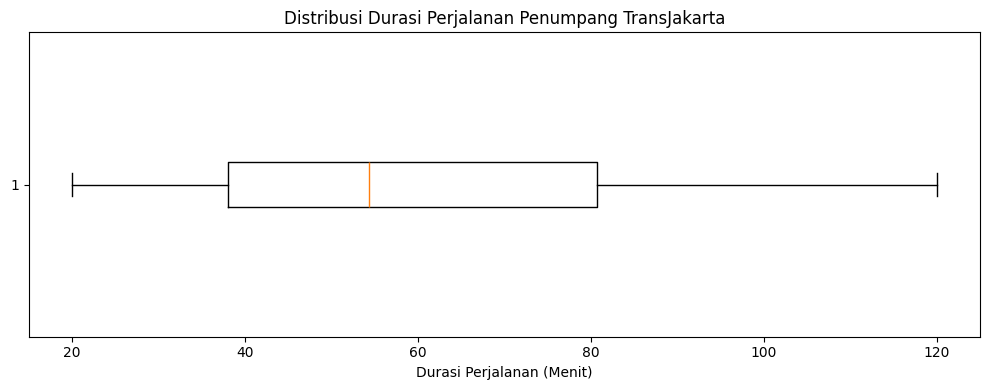

In [38]:
plt.figure(figsize=(10, 4))

plt.boxplot(
    duration,
    vert=False
)

plt.title(
    "Distribusi Durasi Perjalanan Penumpang TransJakarta"
)

plt.xlabel(
    "Durasi Perjalanan (Menit)"
)

plt.tight_layout()
plt.show()

## Hipotesis

**H0:** Tidak terdapat hubungan yang signifikan antara jumlah halte yang dilewati dengan durasi perjalanan penumpang TransJakarta.

**H1:** Terdapat hubungan yang signifikan antara jumlah halte yang dilewati dengan durasi perjalanan penumpang TransJakarta.

Taraf signifikansi yang digunakan adalah α = 0,05.

Metode yang digunakan adalah **Spearman Rank Correlation**.

### **Data untuk Uji Spearman**

menyiapkan data jumlah halte dan durasi perjalanan yang valid untuk digunakan dalam uji korelasi Spearman.

In [39]:
# ==============================
# DATA UNTUK UJI SPEARMAN
# ==============================

df_corr = df_clean[
    df_clean["jumlah_halte"].notna() &
    df_clean["travel_duration_min"].notna() &
    (df_clean["jumlah_halte"] > 0) &
    (df_clean["travel_duration_min"] > 0)
][
    [
        "jumlah_halte",
        "travel_duration_min"
    ]
].copy()

print(
    "Jumlah data untuk uji korelasi:",
    len(df_corr)
)

Jumlah data untuk uji korelasi: 12852


### **Spearman Correlation**

melakukan uji korelasi Spearman untuk mengetahui hubungan antara jumlah halte yang dilewati dengan durasi perjalanan penumpang.

In [40]:
# ==============================
# SPEARMAN CORRELATION
# ==============================

from scipy.stats import spearmanr

rho, p_value = spearmanr(
    df_corr["jumlah_halte"],
    df_corr["travel_duration_min"]
)

alpha = 0.05

print("Spearman rho :", rho)
print("P-value      :", p_value)
print("Alpha        :", alpha)

Spearman rho : -0.00013723920839601143
P-value      : 0.9875879400358003
Alpha        : 0.05


### **Keputusan Hipotesis**

membandingkan nilai p-value dengan alpha 0,05 untuk menentukan apakah H0 ditolak atau gagal ditolak.

In [41]:
# ==============================
# KEPUTUSAN HIPOTESIS
# ==============================

if p_value < alpha:
    print("Keputusan: H0 ditolak.")
    print(
        "Terdapat hubungan yang signifikan "
        "antara jumlah halte yang dilewati "
        "dan durasi perjalanan."
    )
else:
    print("Keputusan: H0 gagal ditolak.")
    print(
        "Tidak terdapat bukti yang cukup untuk "
        "menyatakan adanya hubungan yang signifikan "
        "antara jumlah halte yang dilewati "
        "dan durasi perjalanan."
    )

Keputusan: H0 gagal ditolak.
Tidak terdapat bukti yang cukup untuk menyatakan adanya hubungan yang signifikan antara jumlah halte yang dilewati dan durasi perjalanan.


### **Interpretasi Korelasi**

menentukan arah dan kekuatan hubungan berdasarkan nilai koefisien korelasi Spearman yang diperoleh.

In [42]:
# ==============================
# INTERPRETASI KORELASI
# ==============================

if abs(rho) < 0.20:
    strength = "sangat lemah"
elif abs(rho) < 0.40:
    strength = "lemah"
elif abs(rho) < 0.60:
    strength = "sedang"
elif abs(rho) < 0.80:
    strength = "kuat"
else:
    strength = "sangat kuat"

if rho > 0:
    direction = "positif"
elif rho < 0:
    direction = "negatif"
else:
    direction = "tidak memiliki arah"

print(
    f"Koefisien Spearman menunjukkan hubungan "
    f"{direction} dengan kekuatan {strength}."
)

print(
    f"rho = {rho:.4f}"
)

Koefisien Spearman menunjukkan hubungan negatif dengan kekuatan sangat lemah.
rho = -0.0001


### **Scatter Plot**

menampilkan hubungan antara jumlah halte yang dilewati dengan durasi perjalanan dalam bentuk scatter plot untuk melihat pola hubungan kedua variabel secara visual.

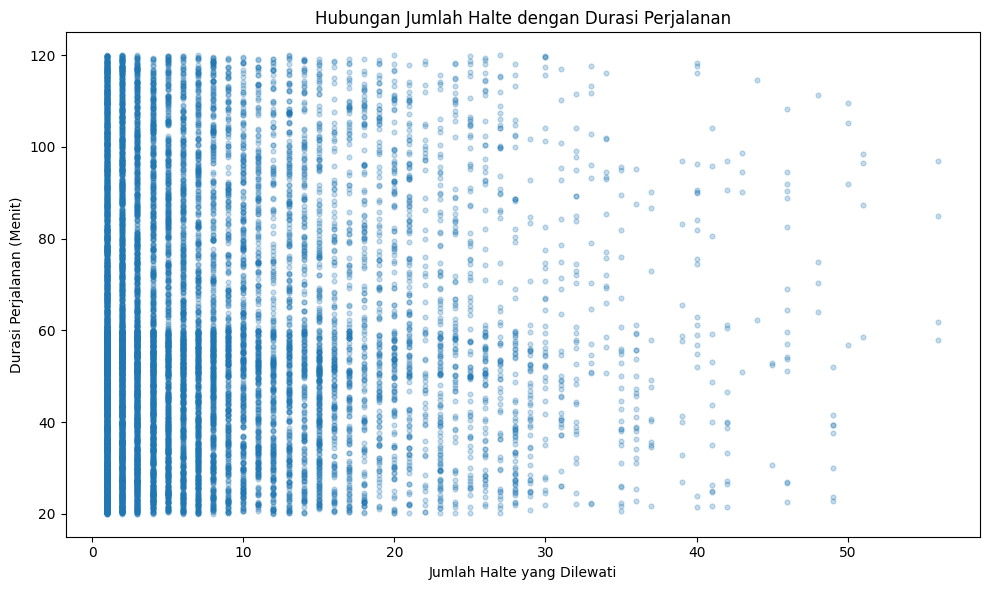

In [43]:
# ==============================
# SCATTER PLOT
# ==============================

plt.figure(figsize=(10, 6))

plt.scatter(
    df_corr["jumlah_halte"],
    df_corr["travel_duration_min"],
    alpha=0.25,
    s=12
)

plt.title(
    "Hubungan Jumlah Halte dengan Durasi Perjalanan"
)

plt.xlabel(
    "Jumlah Halte yang Dilewati"
)

plt.ylabel(
    "Durasi Perjalanan (Menit)"
)

plt.tight_layout()
plt.show()